![Banner](../../../../Images/Banner/07_remote_sensing/09_05_banner_rs_hyperspect.png)


# Narrowband Indices and Vegetation Analysis

Narrow bands let an index target one absorption feature instead of a whole spectral region:
chlorophyll on the red edge, carotenoids and anthocyanins in the green, the xanthophyll cycle at
531 nm, leaf water at 970, 1200 and 1650 nm, and cellulose and lignin in the SWIR. This notebook
uses the narrowband index catalogue of `geolattice.rsense.hyperspectral` on Tanager scenes from three
seasons and climates, maps the red edge position, shows why red edge indices keep working where
NDVI saturates, and adds a custom index.


## Overview

### What a leaf spectrum records

| Region | Main absorbers | Typical indices |
|---|---|---|
| 400 to 500 nm | Chlorophyll a and b, carotenoids | SIPI, CRI |
| 500 to 600 nm | Carotenoids, anthocyanins; xanthophyll cycle at 531 nm | PRI, CRI1, ARI1 |
| 650 to 690 nm | Chlorophyll (red absorption) | NDVI, MCARI, TCARI |
| 690 to 750 nm | Red edge: slope set by chlorophyll content and canopy structure | NDRE, MTCI, CIred_edge, red edge position |
| 750 to 1300 nm | Leaf structure and canopy LAI (scattering); weak water bands at 970 and 1200 nm | NDVI, MTVI2, WBI, NDWI (Gao) |
| 1300 to 2500 nm | Leaf water; dry matter (cellulose, lignin, protein) near 1730, 2100 and 2300 nm | NDII, MSI, CAI, NDLI, NDNI |

### Why narrow bands

Broadband NDVI saturates once the canopy closes (LAI above about 3): red reflectance is near zero
and NIR is high, so further increases in chlorophyll or leaf area barely change the ratio. Indices
built on the **red edge**, where absorption is weaker, keep responding to chlorophyll at high
biomass. Narrow green bands make **pigment** and **photosynthetic efficiency** indices possible (PRI
tracks the de-epoxidation of xanthophylls under excess light), and narrow SWIR bands separate **leaf
water** from **dry matter**, the basis of drought stress, fuel moisture and crop residue mapping.

### The red edge position

The wavelength of the steepest slope between about 680 and 760 nm, the **red edge position (REP)**,
moves to longer wavelengths as chlorophyll increases (a few nm per 10 µg cm⁻²) and to shorter
wavelengths under stress or senescence. It is estimated from the maximum of the first derivative or
with the four point linear interpolation of Guyot and Baret (1988).

### Caveats

Indices respond to everything that changes reflectance at their bands: soil background, canopy
structure, view and sun angles, illumination and atmospheric residuals. They are fast and robust
proxies, but quantitative retrieval (notebook 09_05_05) needs models and field data.


## Narrowband Indices with GeoLattice

`hs.index(cube, name)` computes an index from the bands nearest to its wavelengths (within a
tolerance), so the same name works for Tanager, EMIT, PRISMA, EnMAP or AVIRIS cubes.
`hs.list_indices` and `hs.available_indices` list the catalogue, `hs.register_index` adds new
indices and `hs.red_edge_position` maps the REP.

### Learning objectives

1. Browse the index catalogue and check which indices a sensor supports.
2. Compute and map pigment, red edge, water and dry matter indices.
3. Measure the redundancy between indices.
4. Map the red edge position with two methods.
5. Show NDVI saturation and the advantage of red edge indices in dense canopies.
6. Compare vegetation condition between scenes and seasons.
7. Register a custom index.

### Data

| Scene | Date | Landscape |
|---|---|---|
| Tanager agriculture | 24 February 2025 | Gran Chaco forest, fields and a river on the Bolivia and Argentina border (wet season) |
| Tanager natural lands | 21 February 2025 | Hills of Bosnia and Herzegovina (winter) |
| Tanager ROCX 2025 | 19 September 2025 | Farmland, forest and suburbs near Rochester, New York (late summer) |

### Contents

- Setup
- The index catalogue
- Index maps
- How many independent indices?
- Red edge position
- NDVI saturation and red edge indices
- Three scenes, three seasons
- A custom index
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

GeoLattice 0.3.43


## The index catalogue


In [2]:
cat = pd.DataFrame([{"index": k, "wavelengths (nm)": v.wavelengths, "description": v.description}
                    for k, v in hs.indices.INDICES.items()]).set_index("index")
probe = hs.read_tanager(tanager_file("agriculture"), window=(slice(0, 1), slice(0, 1)))  # Tanager bands
ohs_wl = np.array(hs.io.OHS_WAVELENGTHS)  # OHS band centres
cat["Tanager"] = [k in hs.available_indices(probe) for k in cat.index]  # every index has bands
cat["OHS"] = [bool(np.all(np.min(np.abs(np.subtract.outer(v, ohs_wl)), 1) <= 15))
              for v in cat["wavelengths (nm)"]]  # OHS only reaches 940 nm
print(len(cat), "indices |", int(cat["Tanager"].sum()), "available for Tanager |", int(cat["OHS"].sum()), "for OHS")
cat

32 indices | 32 available for Tanager | 19 for OHS


,wavelengths (nm),description,Tanager,OHS
index,,,,
NDVI,"(800.0, 670.0)",Narrowband NDVI,True,True
EVI,"(800.0, 670.0, 470.0)",Enhanced vegetation index,True,True
OSAVI,"(800.0, 670.0)",Optimized soil-adjusted VI,True,True
MTVI2,"(800.0, 670.0, 550.0)",Modified triangular VI 2 (LAI),True,True
NDRE,"(790.0, 720.0)",Normalized difference red edge,True,True
mND705,"(750.0, 705.0, 445.0)",Modified red-edge ND,True,False
CIred_edge,"(800.0, 720.0)",Red-edge chlorophyll index,True,True
MTCI,"(754.0, 709.0, 681.0)",MERIS terrestrial chlorophyll,True,True
MCARI,"(700.0, 670.0, 550.0)",Modified chlorophyll absorption ratio,True,True


## Index maps

A 400 by 400 pixel window (12 by 12 km) of the agriculture scene covers forest, fields, the river
and a town.


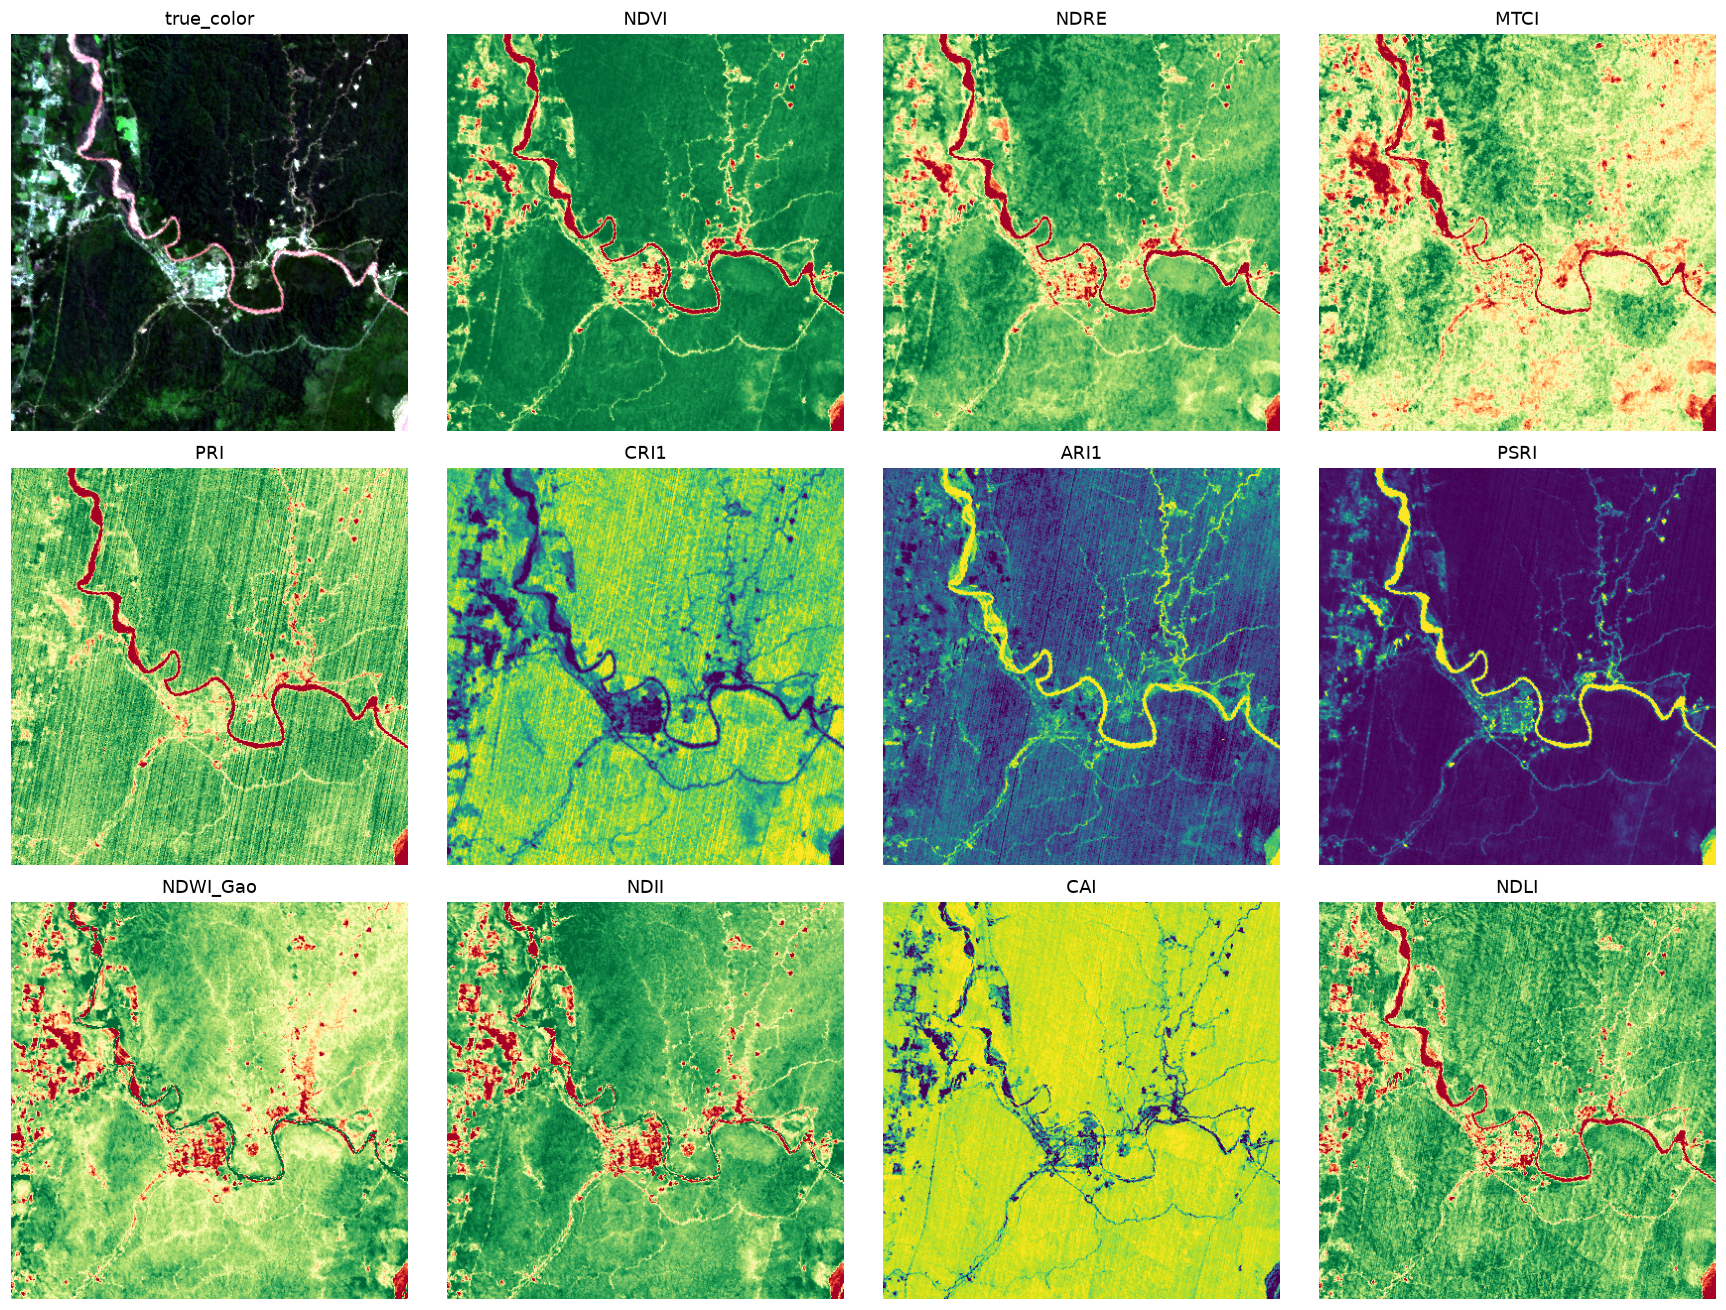

In [3]:
agri = hs.read_tanager(tanager_file("agriculture"), window=(slice(150, 550), slice(200, 600)))  # all bands
NAMES = ["NDVI", "NDRE", "MTCI", "PRI", "CRI1", "ARI1", "PSRI", "NDWI_Gao", "NDII", "CAI", "NDLI", "NBR_hs"]
idx = hs.index(agri, NAMES)  # Dataset, one map per index
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
hs.plot_rgb(agri, "true_color", ax=axes[0, 0])
for ax, n in zip(axes.ravel()[1:], NAMES[:11]):
    v = idx[n]
    ax.imshow(v, cmap="RdYlGn" if n not in ("PSRI", "CAI", "ARI1", "CRI1") else "viridis",
              vmin=np.nanpercentile(v, 2), vmax=np.nanpercentile(v, 98))
    ax.set_title(n); ax.axis("off")
plt.tight_layout()
plt.show()

NDVI, NDRE and MTCI all outline the forest, but with different contrast inside it: NDVI is almost
uniform over the closed canopy, while the red edge indices still vary. The water indices (NDWI and
NDII) are high wherever leaves are wet and dense, and the town and bare ground stand out as low.
The cellulose absorption index (CAI) is nearly uniform over this green wet season landscape and drops
only over the river and wet ground, since there is little dry plant matter to detect. PRI, CRI1, ARI1
and PSRI show finer patterns tied to pigments and illumination, and all of them mark the sediment
laden river strongly.


## How many independent indices?


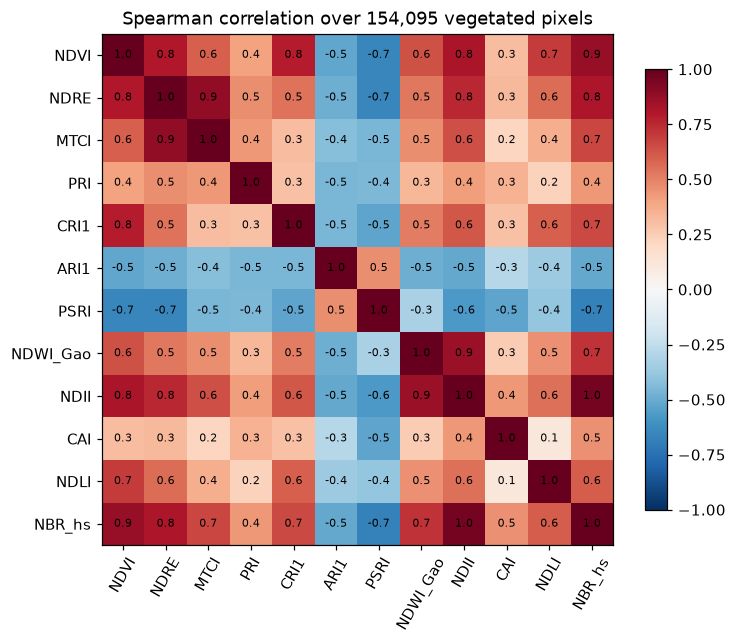

In [4]:
veg = (idx["NDVI"] > 0.5).values  # vegetated pixels
T = pd.DataFrame({n: idx[n].values[veg] for n in NAMES}).dropna()  # one row per pixel
corr = T.corr(method="spearman")  # rank correlation between indices
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NAMES)), NAMES, rotation=60); ax.set_yticks(range(len(NAMES)), NAMES)
for i in range(len(NAMES)):
    for j in range(len(NAMES)):
        ax.text(j, i, f"{corr.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_title(f"Spearman correlation over {len(T):,} vegetated pixels")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Several groups emerge. NDVI, NDII and the burn ratio correlate at 0.8 to 1.0 in this canopy, because
greener canopies here are also wetter; the red edge indices NDRE and MTCI form a tight pair (0.9);
the anthocyanin and senescence indices (ARI1, PSRI) run against all the greenness indices; PRI, CAI
and NDLI are only weakly related to the rest and carry the most independent information. In a model it is better to choose one index per group, or to
use the full spectrum (notebook 09_05_05), than to stack a dozen indices that measure the same thing.


## Red edge position


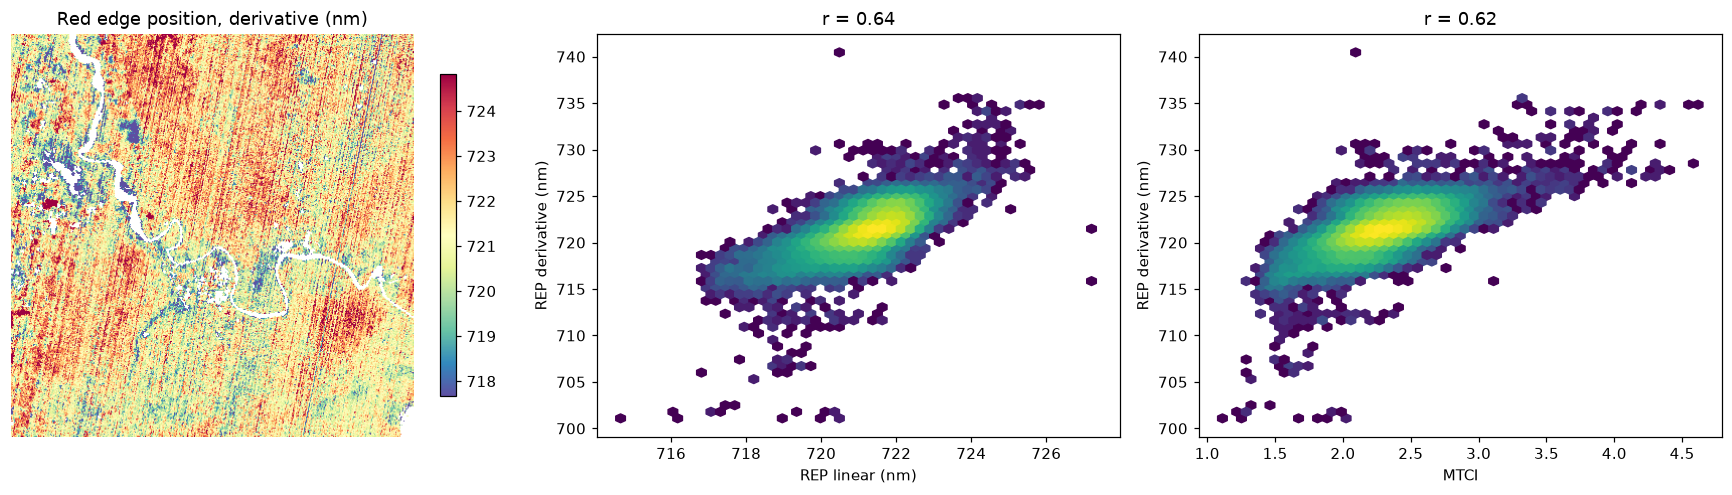

       derivative    linear
count    154095.0  154095.0
mean        721.5     721.4
std           1.7       0.8
min         701.1     714.7
25%         720.6     721.0
50%         721.5     721.4
75%         722.4     721.9
max         740.5     727.3


In [5]:
rep_d = hs.red_edge_position(agri)  # maximum first derivative, parabolic refinement
rep_l = hs.red_edge_position(agri, method="linear")  # four point linear interpolation
ok = veg & np.isfinite(rep_d.values) & np.isfinite(rep_l.values)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
im = axes[0].imshow(np.where(veg, rep_d, np.nan), cmap="Spectral_r", vmin=np.nanpercentile(rep_d.values[ok], 2),
                    vmax=np.nanpercentile(rep_d.values[ok], 98))
axes[0].set_title("Red edge position, derivative (nm)"); axes[0].axis("off"); plt.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].hexbin(rep_l.values[ok], rep_d.values[ok], gridsize=50, bins="log", cmap="viridis")
axes[1].set(xlabel="REP linear (nm)", ylabel="REP derivative (nm)", title=f"r = {np.corrcoef(rep_l.values[ok], rep_d.values[ok])[0, 1]:.2f}")
axes[2].hexbin(idx["MTCI"].values[ok], rep_d.values[ok], gridsize=50, bins="log", cmap="viridis")
axes[2].set(xlabel="MTCI", ylabel="REP derivative (nm)", title=f"r = {np.corrcoef(idx['MTCI'].values[ok], rep_d.values[ok])[0, 1]:.2f}")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"derivative": rep_d.values[ok], "linear": rep_l.values[ok]}).describe().round(1))

Both methods place the red edge of this canopy near 721 nm, and the spread is small: a few nm
across the whole window, close to the 5 nm band spacing. In such a narrow range the two methods agree
only moderately (r about 0.64): the derivative method follows the sampled spectrum and is noisier,
the linear method assumes a straight red edge between 700 and 740 nm and compresses the range.
MTCI, which uses three bands on the red edge, is related to the REP to a similar degree (r about
0.62). Use one method consistently when comparing dates or sites, and expect the REP to be most
useful where chlorophyll varies more than in this uniformly green forest.


## NDVI saturation and red edge indices

If NDVI saturates, it should flatten while a red edge index keeps rising as canopy greenness
increases. A plot against the red edge chlorophyll index (CIred_edge, a ratio that does not
saturate) shows it.


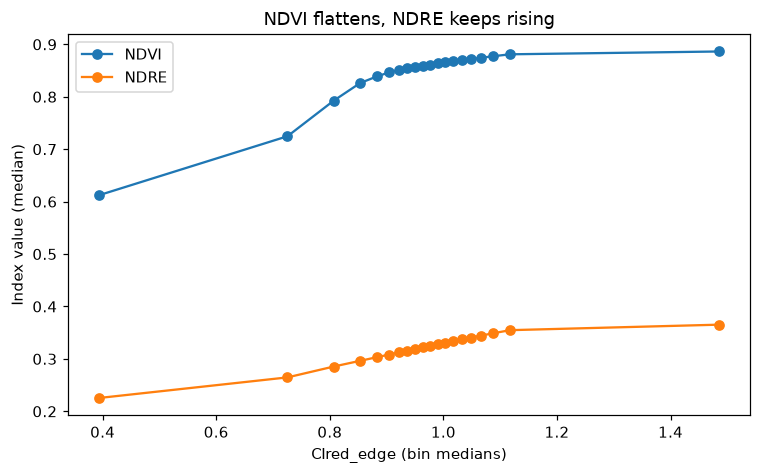

slope in the densest 8 bins relative to the sparsest 8 bins: {'NDVI': np.float64(0.08), 'NDRE': np.float64(0.38)}


In [6]:
ci = hs.index(agri, "CIred_edge").values  # R800 / R720 - 1
v = veg & np.isfinite(ci)
bins = np.quantile(ci[v], np.linspace(0, 1, 21))  # 20 equal-count bins of CIred_edge
mid = 0.5 * (bins[1:] + bins[:-1])
med = {n: [np.nanmedian(idx[n].values[v][(ci[v] >= a) & (ci[v] < b)]) for a, b in zip(bins[:-1], bins[1:])]
       for n in ["NDVI", "NDRE"]}
fig, ax = plt.subplots(figsize=(8, 4.5))
for n, m in med.items():
    ax.plot(mid, m, "o-", label=n)
ax.set(xlabel="CIred_edge (bin medians)", ylabel="Index value (median)", title="NDVI flattens, NDRE keeps rising")
ax.legend()
plt.show()
slope = {n: np.polyfit(mid[-8:], np.array(m)[-8:], 1)[0] / np.polyfit(mid[:8], np.array(m)[:8], 1)[0] for n, m in med.items()}
print("slope in the densest 8 bins relative to the sparsest 8 bins:", {k: round(v, 2) for k, v in slope.items()})

Over sparse vegetation both indices rise with CIred_edge; in the densest canopy NDVI's slope drops to
a small fraction of its initial value, while NDRE keeps a larger share of its sensitivity (compare
the two slope ratios printed above). This is the practical reason to use red edge indices for
nitrogen and chlorophyll in closed crops and forests.


## Three scenes, three seasons

Vegetation from the Chaco in the wet season, Bosnian hills in winter and New York farmland and forest
in late summer. Each scene is read with only the bands the indices need (14 bands), and pixels
with NDVI above 0.3 are compared; at most 20,000 pixels are sampled per scene.


Chaco, Feb (wet season): 14 bands read, 20,000 vegetated pixels sampled


Bosnia, Feb (winter): 14 bands read, 20,000 vegetated pixels sampled


New York, Sep (late summer): 14 bands read, 20,000 vegetated pixels sampled


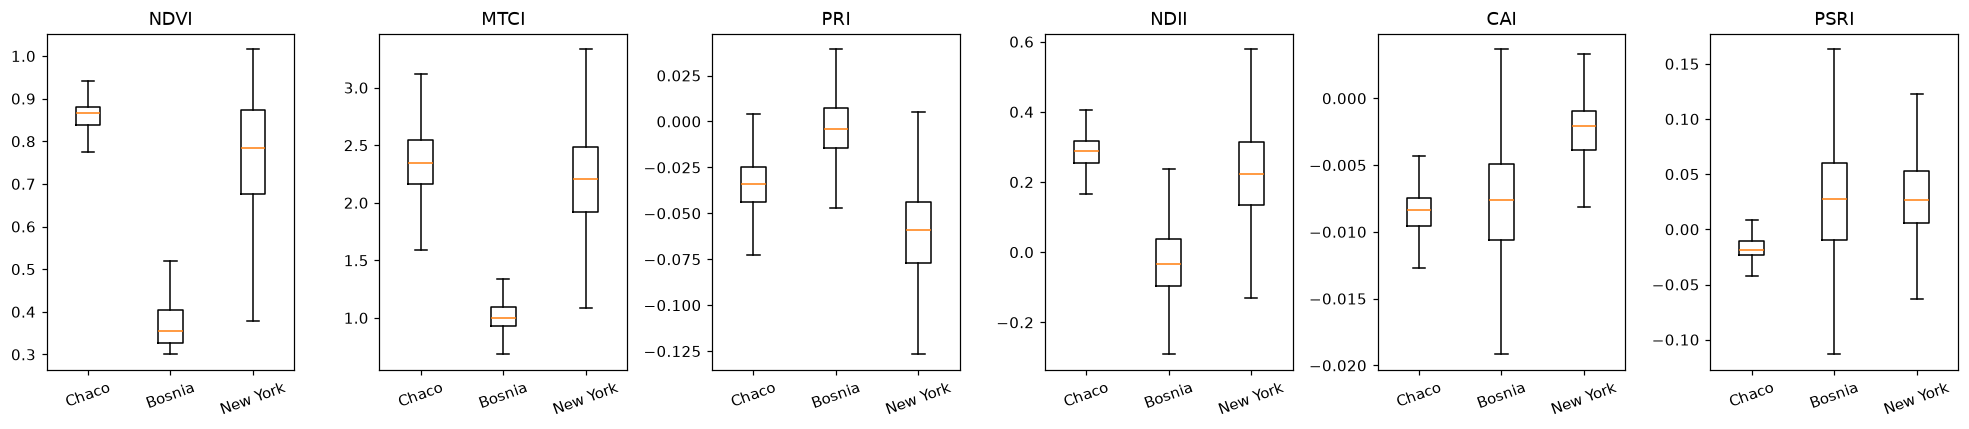

,NDVI,MTCI,PRI,NDII,CAI,PSRI
scene,,,,,,
"Bosnia, Feb (winter)",0.355,1.003,-0.004,-0.032,-0.008,0.028
"Chaco, Feb (wet season)",0.865,2.342,-0.034,0.289,-0.008,-0.019
"New York, Sep (late summer)",0.784,2.207,-0.059,0.223,-0.002,0.026


In [7]:
COMPARE = ["NDVI", "MTCI", "PRI", "NDII", "CAI", "PSRI"]
need = sorted({float(w) for n in COMPARE for w in hs.indices.INDICES[n].wavelengths})  # wavelengths used
bands = sorted({hs.band_index(probe, w) for w in need})  # nearest Tanager bands
rows = []
for cat_name, label in [("agriculture", "Chaco, Feb (wet season)"), ("natural-lands", "Bosnia, Feb (winter)"),
                        ("ROCX2025", "New York, Sep (late summer)")]:
    c = hs.read_tanager(tanager_file(cat_name), bands=bands)  # whole scene, needed bands only
    d = hs.index(c, COMPARE).to_dataframe()[COMPARE].dropna()  # one row per pixel
    d = d[d["NDVI"] > 0.3].sample(20000, random_state=0) if (d["NDVI"] > 0.3).sum() > 20000 else d[d["NDVI"] > 0.3]
    rows.append(d.assign(scene=label))
    print(f"{label}: {len(bands)} bands read, {(d['NDVI'] > 0.3).sum():,} vegetated pixels sampled")
comp = pd.concat(rows)
fig, axes = plt.subplots(1, len(COMPARE), figsize=(18, 4))
for ax, n in zip(axes, COMPARE):
    ax.boxplot([comp.loc[comp.scene == s, n] for s in comp.scene.unique()], showfliers=False)
    ax.set_xticks([1, 2, 3], ["Chaco", "Bosnia", "New York"], rotation=20); ax.set_title(n)
plt.tight_layout()
plt.show()
comp.groupby("scene")[COMPARE].median().round(3)

The table of medians summarises the boxplots. The Chaco wet season canopy is the greenest and
wettest (highest NDVI, MTCI and NDII, lowest PSRI). The Bosnian winter scene's "vegetated" pixels
barely pass the NDVI threshold (median 0.36), with low MTCI, negative NDII and a higher senescence
index: dormant grass, leafless deciduous forest and conifers rather than green leaves. The late
summer New York scene is almost as green as the Chaco but has the highest CAI (dry plant matter, as
in ripening or harvested fields) and a senescence index similar to Bosnia's. PRI differs too, but it
also depends on sun angle and illumination, so its scene medians should not be read as stress alone.
Indices make such contrasts between places and seasons quick to quantify.


## A custom index

`hs.register_index` adds an index by name, wavelengths and formula; the formula receives one
reflectance array per wavelength. Here the green chlorophyll index (Gitelson et al. 2003),
`CIgreen = R800 / R550 - 1`, is added and compared with CIred_edge.


CIgreen in catalogue: True | Spearman r with CIred_edge: 0.922


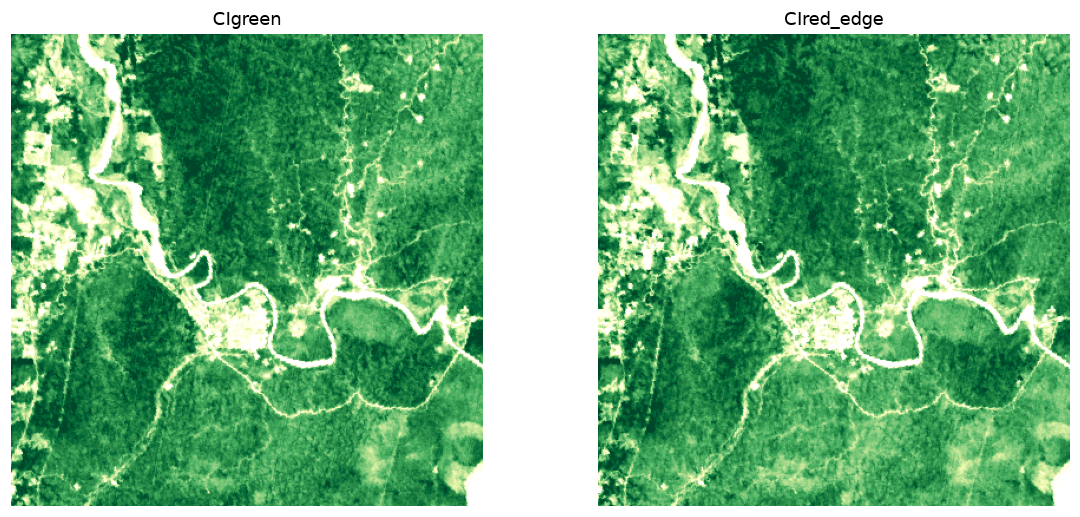

In [8]:
hs.register_index("CIgreen", [800, 550], lambda r800, r550: r800 / r550 - 1,
                  description="Green chlorophyll index", reference="Gitelson et al. 2003")
cig = hs.index(agri, "CIgreen")  # works like any built in index
both = np.isfinite(cig.values) & v
print("CIgreen in catalogue:", "CIgreen" in hs.list_indices(),
      "| Spearman r with CIred_edge:", round(pd.Series(cig.values[both]).corr(pd.Series(ci[both]), method="spearman"), 3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (n, a) in zip(axes, [("CIgreen", cig.values), ("CIred_edge", ci)]):
    ax.imshow(np.where(veg, a, np.nan), cmap="YlGn", vmin=np.nanpercentile(a[veg], 2), vmax=np.nanpercentile(a[veg], 98))
    ax.set_title(n); ax.axis("off")
plt.tight_layout()
plt.show()

## Summary and exercises

**Key points**

- Narrowband indices target single absorption features: pigments, red edge, leaf water and dry
  matter. Defined by wavelength, they run on any imaging spectrometer that covers the bands.
- Many indices are strongly correlated; choose one per group or use full spectrum models.
- The red edge position and red edge indices respond to chlorophyll where NDVI saturates.
- Index distributions separate green, dormant and senescent vegetation between places and seasons.
- Custom indices are one line with `hs.register_index`.

**`geolattice.rsense.hyperspectral` functions used:** `read_tanager`, `index`, `list_indices`,
`available_indices`, `red_edge_position`, `register_index`, `band_index`, `plot_rgb`.

**Exercises**

1. Compute `hs.index(agri, "PRI", width=10)` (averaging bands over 10 nm). Does the map get less
   noisy?
2. Map NDNI and NDLI over the agriculture window. Do they show patterns that NDVI does not?
3. Compute the REP for the ROCX scene and compare the distribution with the Chaco scene.
4. Register the moisture index `NDMI_hs = (R860 - R1640) / (R860 + R1640)` and compare it with NDII.
